<a href="https://colab.research.google.com/github/dhuya3011-oss/email-spam-detection/blob/main/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/dhuya3011-oss/email-spam-detection.git
%cd email-spam-detection
!pip install -q -r requirements.txt

Cloning into 'email-spam-detection'...
remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (16/16), done.
remote: Total 21 (delta 4), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (21/21), 2.82 MiB | 11.68 MiB/s, done.
Resolving deltas: 100% (4/4), done.
/content/email-spam-detection


In [ ]:
import pandas as pd
df = pd.read_csv("dataset/emails.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(5728, 2)
['text', 'spam']


,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


In [ ]:
print(df["spam"].value_counts())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate emails:", df.duplicated(subset="text").sum())

spam
0    4360
1    1368
Name: count, dtype: int64

Missing values:
 text    0
spam    0
dtype: int64

Duplicate emails: 33


In [ ]:
print("SPAM example:\n", df[df.spam == 1]["text"].iloc[0][:400])
print("\nHAM example:\n", df[df.spam == 0]["text"].iloc[0][:400])

SPAM example:
 Subject: naturally irresistible your corporate identity  lt is really hard to recollect a company : the  market is full of suqgestions and the information isoverwhelminq ; but a good  catchy logo , stylish statlonery and outstanding website  will make the task much easier .  we do not promise that havinq ordered a iogo your  company will automaticaily become a world ieader : it isguite ciear that 

HAM example:
 Subject: hello guys ,  i ' m " bugging you " for your completed questionnaire and for a one - page  bio / statement on your thoughts on " business edu and the new economy " . if  my records are incorrect please re - ship your responses to me . i want to  put everything together next week so that i can ship it back to everyone .  the questionnaire is attached as well as copies of the bio pages for 


       count         mean          std   min     25%     50%      75%      max
spam                                                                          
0     4360.0  1631.918119  1959.664549  13.0  577.75  1122.0  2037.25  43952.0
1     1368.0  1317.257310  2271.372893  18.0  401.50   693.5  1250.25  28432.0


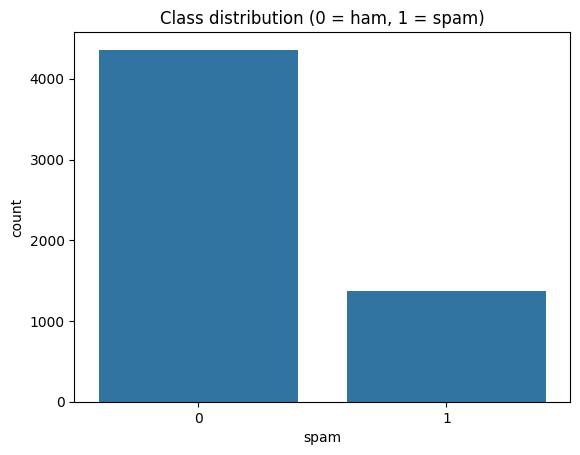

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df["length"] = df["text"].str.len()
print(df.groupby("spam")["length"].describe())

sns.countplot(x="spam", data=df)
plt.title("Class distribution (0 = ham, 1 = spam)")
plt.show()

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("dataset/emails.csv")
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print("After dedup:", df.shape)

X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["spam"],
    test_size=0.2, random_state=42, stratify=df["spam"]
)
print(len(X_train), "train /", len(X_test), "test")

After dedup: (5695, 2)
4556 train / 1139 test


In [10]:
from src.preprocess import clean_text
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("tfidf", TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 2), min_df=2)),
    ("nb", MultinomialNB(alpha=0.1)),
])
model.fit(X_train, y_train)
print("Training done")

Training done


Accuracy: 0.9921
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       865
        spam       1.00      0.97      0.98       274

    accuracy                           0.99      1139
   macro avg       0.99      0.98      0.99      1139
weighted avg       0.99      0.99      0.99      1139



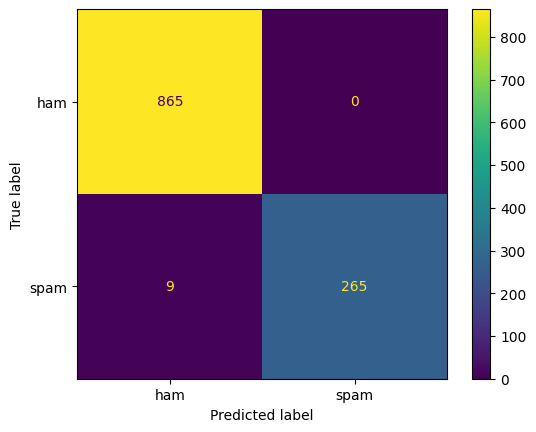

In [11]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

preds = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, preds), 4))
print(classification_report(y_test, preds, target_names=["ham", "spam"]))

ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=["ham", "spam"])
plt.show()

In [12]:
tests = [
    "Subject: Congratulations! You won a free iPhone, click here now",
    "Subject: Meeting moved to 3pm, please review the attached report",
]
for t in tests:
    p = model.predict_proba([t])[0][1]
    print(f"{p:.1%} spam -> {t}")

29.6% spam -> Subject: Congratulations! You won a free iPhone, click here now
1.0% spam -> Subject: Meeting moved to 3pm, please review the attached report


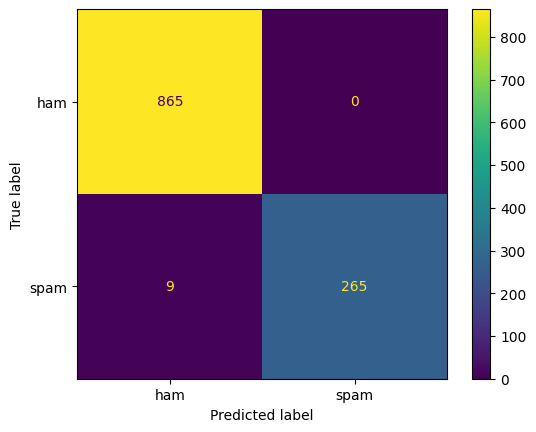

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
import os
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from google.colab import files

os.makedirs("models", exist_ok=True)
os.makedirs("images", exist_ok=True)

joblib.dump(model, "models/spam_model.joblib")

ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=["ham", "spam"])
plt.savefig("images/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

files.download("models/spam_model.joblib")
files.download("images/confusion_matrix.png")